# PROYEK AKHIR SAINS DATA (IF2515403)
## KLASIFIKASI RISIKO GANGGUAN TIDUR BERDASARKAN POLA HIDUP DAN BIOMETRIK

---

## 1. Business Understanding

### A. Latar Belakang Masalah
Kualitas dan kuantitas tidur merupakan pilar fundamental dalam menjaga stabilitas kesehatan fisik, mental, dan fungsi intelektual manusia. Di era modern, khususnya pada kalangan mahasiswa dan tenaga kerja produktif, beban tugas/pekerjaan yang tinggi, jam kerja lembur (*work hours*), tingkat stres (*stress score*), serta kebiasaan menatap layar gawai larut malam (*screen time before bed*) memicu penurunan durasi tidur secara drastis.

Fenomena kurang tidur ini memberikan dampak negatif nyata:
1. **Penurunan Status Kesehatan**: Meningkatnya risiko ketidakseimbangan biometrik tubuh (seperti fluktuasi detak jantung istirahat dan BMI), sistem imun melemah, dan kelelahan kronis.
2. **Penurunan Konsentrasi dan Performa Intelektual**: Kurang tidur mengganggu fase tidur nyenyak (*deep sleep*) dan fase REM, yang berdampak langsung pada turunnya konsentrasi belajar, daya ingat, dan skor performa kognitif harian (*cognitive performance score*).

Oleh karena itu, diperlukan pendekatan prediktif berbasis machine learning yang mampu mengidentifikasi risiko gangguan tidur seseorang secara dini dan preventif berdasarkan karakteristik pola hidup dan data biometriknya.

### B. Rumusan Masalah
1. Bagaimana karakteristik faktor demografi, biometrik, dan kebiasaan gaya hidup yang memengaruhi pola serta kualitas tidur seseorang?
2. Bagaimana cara mengidentifikasi dan mengklasifikasikan tingkat risiko gangguan tidur (*sleep_disorder_risk*) berdasarkan data pola hidup dan biometrik?
3. Bagaimana merancang *pipeline Data Preparation* yang tepat dan terstandarisasi untuk menangani permasalahan kualitas data (data hilang, outlier, encoding fitur, dan ketidakseimbangan kelas)?

### C. Tujuan Analisis
1. Mengidentifikasi pola serta hubungan antara metrik gaya hidup dan biometrik terhadap risiko gangguan tidur melalui analisis data eksploratif (*Data Understanding*).
2. Membangun dan menerapkan *pipeline* penyiapan data (*Data Preparation*) yang terstandarisasi meliputi penanganan *missing values*, *outliers*, pengkodean data (*encoding*), penskalaan (*scaling*), dan penanganan ketidakseimbangan kelas (*class imbalance*).
3. Membangun sistem model machine learning klasifikasi yang mampu memprediksi tingkat risiko gangguan tidur (*Healthy, Mild, Moderate, Severe*) secara akurat dan otomatis.

### D. Kriteria Kesuksesan (Success Criteria)
1. **Kriteria Model & Metrik Evaluasi**: Model klasifikasi yang dikembangkan ditargetkan mencapai nilai ambang batas performa minimal **≥ 85%** pada seluruh metrik evaluasi utama: **Accuracy, Precision, Recall, dan Macro F1-Score**.
2. **Kriteria Data Preparation**: Menghasilkan dataset bersih siap latih dengan **0% missing values**, nilai ekstrem (*outlier*) tertangani secara statistik, fitur terstandarisasi, dan bebas dari potensi kebocoran data (*data leakage*).


## 2. Data Understanding

### A. Gambaran Umum Dataset
Dataset `dataset_GANGGUAN_TIDUR.csv` memuat **100.000 observasi sampel** dan **32 variabel (kolom)** yang merekam metrik demografi, biometrik, kebiasaan sebelum tidur, aktivitas fisik harian, hingga tingkat risiko gangguan tidur.

### B. Kamus Data (Data Dictionary)
Sesuai rubrik penilaian (Skor 5: *Seluruh atribut dan tipe data dijelaskan dengan jelas*), berikut adalah deskripsi lengkap seluruh 32 atribut dalam dataset:

| No | Nama Kolom | Tipe Data | Kategori Fitur | Deskripsi & Satuan |
|:---|:---|:---|:---|:---|
| 1 | `person_id` | Float / Int | Identifier | ID unik pengenal setiap individu/responden |
| 2 | `age` | Float / Int | Demografi | Usia responden (tahun) |
| 3 | `gender` | String / Object | Demografi | Jenis kelamin (*Male, Female, Other*) |
| 4 | `occupation` | String / Object | Demografi | Profesi/pekerjaan (*Student, Doctor, Nurse, dll.*) |
| 5 | `bmi` | Float | Biometrik | Indeks Massa Tubuh / Body Mass Index ($kg/m^2$) |
| 6 | `country` | String / Object | Demografi | Negara domisili responden |
| 7 | `sleep_duration_hrs` | Float | Pola Tidur | Rata-rata durasi tidur harian (jam) |
| 8 | `sleep_quality_score` | Float | Pola Tidur | Skor kualitas tidur subjektif (skala 1 - 10) |
| 9 | `rem_percentage` | Float | Pola Tidur | Persentase fase tidur REM (*Rapid Eye Movement*) (%) |
| 10 | `deep_sleep_percentage` | Float | Pola Tidur | Persentase fase tidur nyenyak / *Deep Sleep* (%) |
| 11 | `sleep_latency_mins` | Float | Pola Tidur | Waktu yang dibutuhkan hingga benar-benar terlelap (menit) |
| 12 | `wake_episodes_per_night` | Float / Int | Pola Tidur | Frekuensi terbangun di tengah tidur malam (kali) |
| 13 | `caffeine_mg_before_bed` | Float | Gaya Hidup | Konsumsi kafein sebelum tidur (miligram / mg) |
| 14 | `alcohol_units_before_bed` | Float | Gaya Hidup | Konsumsi alkohol sebelum tidur (unit alkohol) |
| 15 | `screen_time_before_bed_mins` | Float | Gaya Hidup | Penggunaan layar gawai sebelum tidur (menit) |
| 16 | `exercise_day` | Float / Int | Aktivitas | Melakukan olahraga pada hari itu (1 = Ya, 0 = Tidak) |
| 17 | `steps_that_day` | Float | Aktivitas | Jumlah langkah fisik harian yang dicatat (langkah) |
| 18 | `nap_duration_mins` | Float | Pola Tidur | Durasi tidur siang (menit) |
| 19 | `stress_score` | Float | Psikologis | Skor tingkat stres harian (skala 1 - 10) |
| 20 | `work_hours_that_day` | Float | Aktivitas | Total jam kerja / belajar pada hari tersebut (jam) |
| 21 | `chronotype` | String / Object | Sirkadian | Tipe ritme biologis (*Morning, Evening, Neutral*) |
| 22 | `mental_health_condition` | String / Object | Psikologis | Status kesehatan mental (*Healthy, Anxiety, Depression, Both*) |
| 23 | `heart_rate_resting_bpm` | Float | Biometrik | Detak jantung istirahat saat tidur (BPM - denyut per menit) |
| 24 | `sleep_aid_used` | Float / Int | Medis | Penggunaan obat bantuan tidur (1 = Ya, 0 = Tidak) |
| 25 | `shift_work` | Float / Int | Pekerjaan | Menjalani jadwal kerja giliran / shift malam (1 = Ya, 0 = Tidak) |
| 26 | `room_temperature_celsius` | Float | Lingkungan | Suhu ruangan kamar tidur ($^\circ C$) |
| 27 | `weekend_sleep_diff_hrs` | Float | Pola Tidur | Selisih durasi tidur hari kerja vs akhir pekan (jam) |
| 28 | `season` | String / Object | Lingkungan | Musim saat data direkam (*Spring, Summer, Autumn, Winter*) |
| 29 | `day_type` | String / Object | Lingkungan | Tipe hari pencatatan data (*Weekday* atau *Weekend*) |
| 30 | `cognitive_performance_score` | Float | Kognitif | Skor performa kognitif/konsentrasi (skala 0 - 100) |
| 31 | `sleep_disorder_risk` | String / Object | **Target** | **Kategori risiko gangguan tidur (*Healthy, Mild, Moderate, Severe*)** |
| 32 | `felt_rested` | Float / Int | Pola Tidur | Merasa segar dan bugar saat bangun (1 = Ya, 0 = Tidak) |


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Konfigurasi agar Pandas menampilkan SEMUA 32 kolom tanpa terpotong (...)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 50)

# 1. Memuat dataset
df = pd.read_csv('dataset_GANGGUAN_TIDUR.csv')

# 2. Menampilkan 20 sampel data acak (Memenuhi Skor 5 Rubrik: Minimal 20 Sampel)
print('=== 20 Sampel Data Representatif (Seluruh 32 Kolom Tampil) ===')
display(df.sample(20, random_state=42))

# 3. Mengecek tipe data dan total missing values secara lengkap (32 Kolom)
print('\n=== Informasi Atribut, Tipe Data, & Null (Lengkap) ===')
df.info(verbose=True, show_counts=True)

# 4. Menampilkan Karakteristik Data / Statistik Deskriptif untuk Seluruh Fitur
print('\n=== Statistik Deskriptif (Seluruh 32 Fitur Ditranspose agar Mudah Dibaca) ===')
display(df.describe(include='all').T)


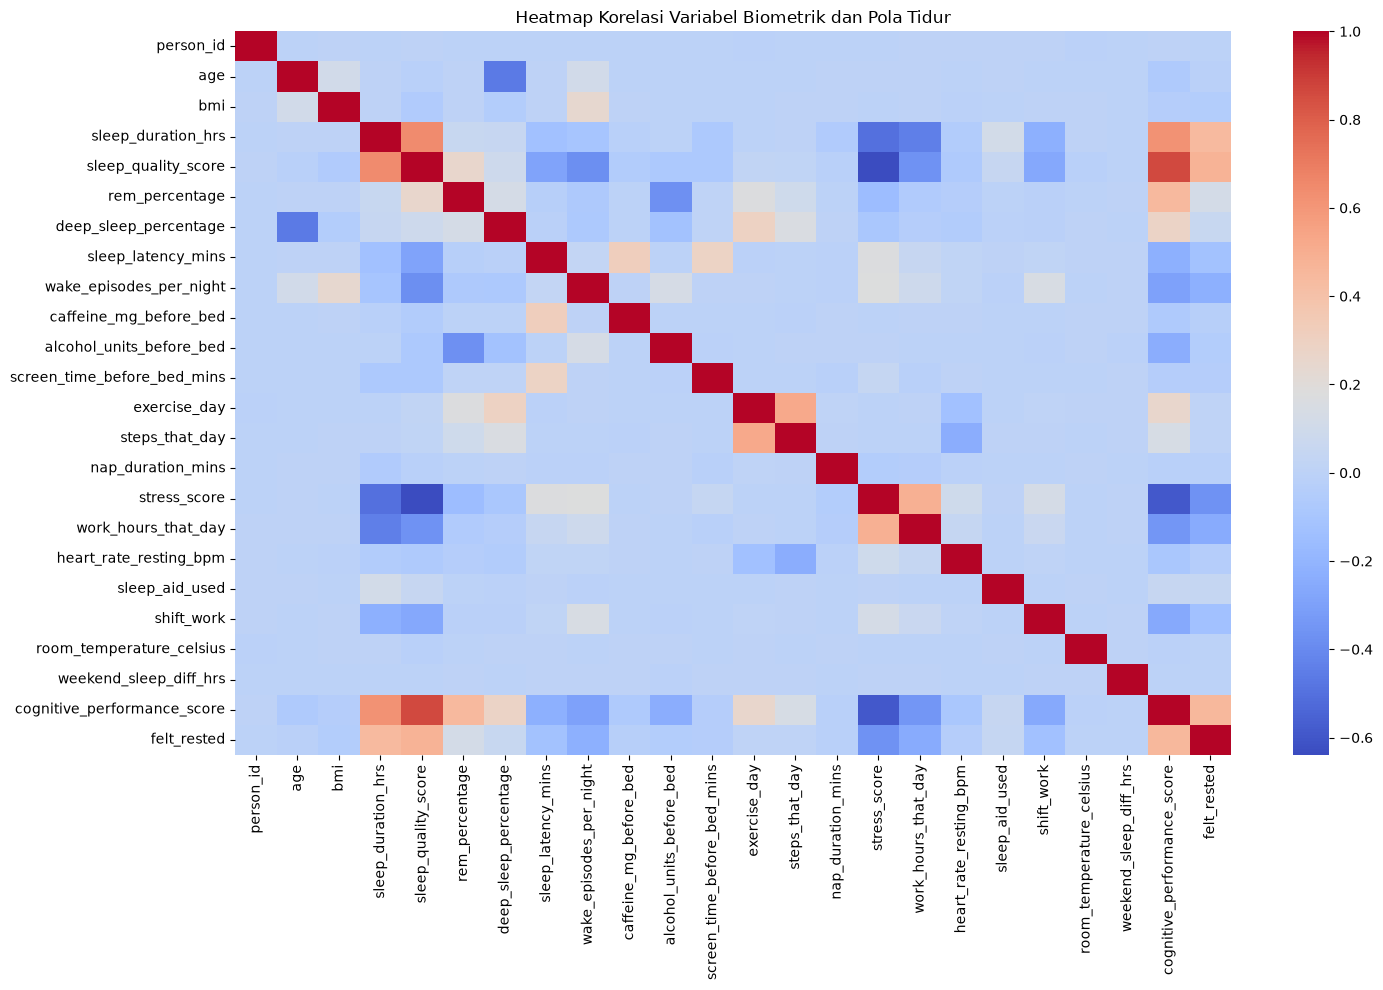

In [2]:
# 5. Visualisasi Korelasi (Heatmap) untuk melihat hubungan antar variabel
# Memilih hanya kolom numerik agar heatmap tidak error
kolom_numerik = df.select_dtypes(include=['float64', 'int64'])

plt.figure(figsize=(15, 10))
# Membuat heatmap korelasi (numeric_only=True diperlukan di pandas 3.x)
sns.heatmap(kolom_numerik.corr(numeric_only=True), annot=False, cmap='coolwarm')
plt.title("Heatmap Korelasi Variabel Biometrik dan Pola Tidur")
plt.tight_layout()
plt.show()

### 6. Analisis Tambahan untuk Memperkuat Data Understanding (CRISP-DM)

In [3]:
# A. Memeriksa jumlah dan persentase missing values secara mendetail
missing_data = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({'Jumlah Missing': missing_data, 'Persentase (%)': missing_percent})
print("=== Analisis Missing Values per Kolom ===")
display(missing_df[missing_df['Jumlah Missing'] > 0].sort_values(by='Jumlah Missing', ascending=False))

# B. Memeriksa adanya duplikasi data
jumlah_duplikat = df.duplicated().sum()
print(f"\n=== Analisis Duplikasi Data ===\nJumlah baris terduplikasi: {jumlah_duplikat}")

=== Analisis Missing Values per Kolom ===


,Jumlah Missing,Persentase (%)
person_id,10000,10.0
age,10000,10.0
gender,10000,10.0
occupation,10000,10.0
bmi,10000,10.0
country,10000,10.0
sleep_duration_hrs,10000,10.0
sleep_quality_score,10000,10.0
rem_percentage,10000,10.0
deep_sleep_percentage,10000,10.0



=== Analisis Duplikasi Data ===
Jumlah baris terduplikasi: 0


=== Distribusi Kelas Target (sleep_disorder_risk) ===


sleep_disorder_risk
Healthy     54156
Mild        33479
Moderate     8299
Severe       4066
Name: count, dtype: int64

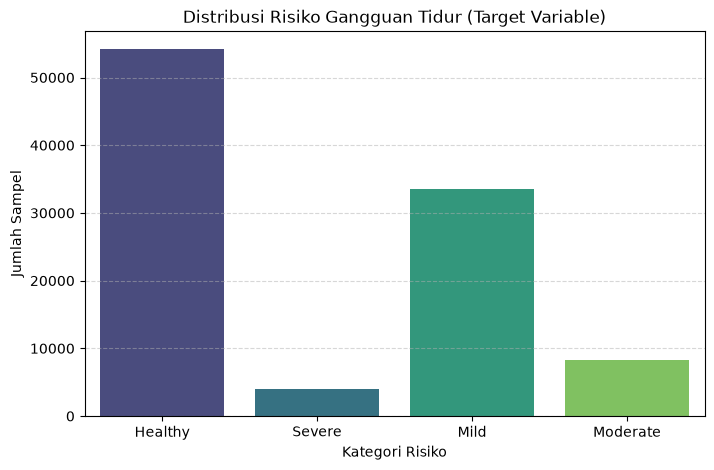

In [4]:
# C. Distribusi Variabel Target (sleep_disorder_risk)
print("=== Distribusi Kelas Target (sleep_disorder_risk) ===")
target_counts = df['sleep_disorder_risk'].value_counts(dropna=False)
display(target_counts)

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='sleep_disorder_risk', palette='viridis', hue='sleep_disorder_risk', legend=False)
plt.title("Distribusi Risiko Gangguan Tidur (Target Variable)")
plt.xlabel("Kategori Risiko")
plt.ylabel("Jumlah Sampel")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()


### C. Analisis Proporsi Kategori Menggunakan Pie Chart (Slide 10)
Sesuai Slide 10, **Pie Chart** digunakan untuk menunjukkan proporsi setiap kategori terhadap keseluruhan data sehingga memudahkan interpretasi komposisi data.


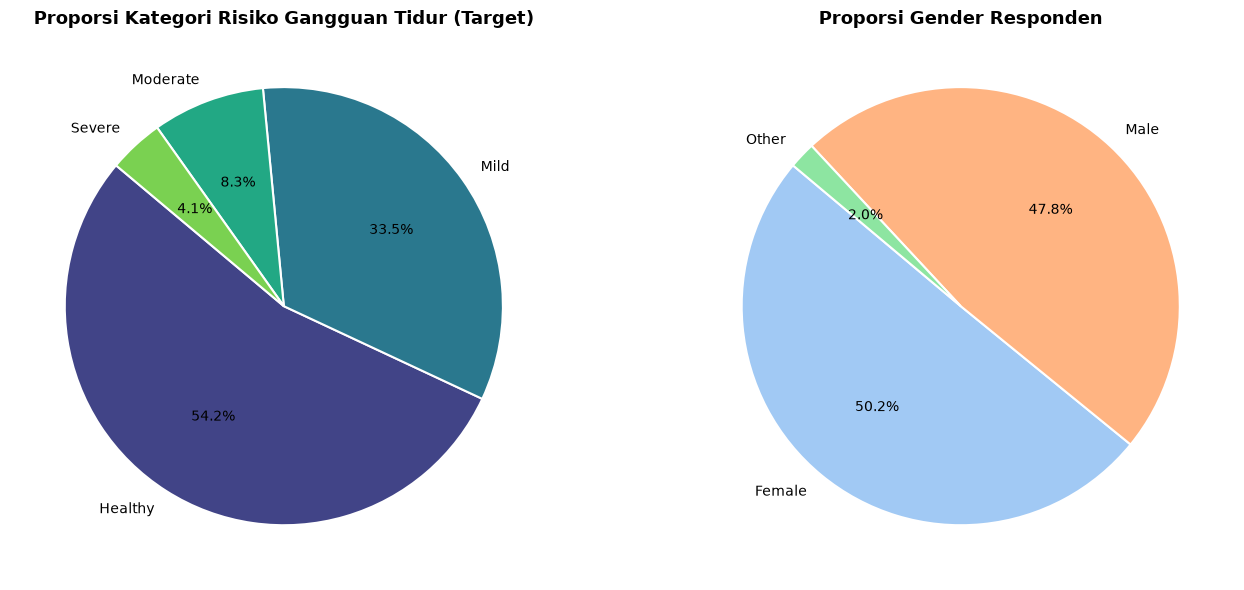

In [5]:
# Visualisasi Proporsi Menggunakan Pie Chart (Slide 10)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 1. Pie Chart untuk Distribusi Kelas Target (Risiko Gangguan Tidur)
target_counts = df['sleep_disorder_risk'].value_counts()
axes[0].pie(target_counts, labels=target_counts.index, autopct='%1.1f%%',
            startangle=140, colors=sns.color_palette('viridis', len(target_counts)),
            wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
axes[0].set_title('Proporsi Kategori Risiko Gangguan Tidur (Target)', fontsize=13, fontweight='bold')

# 2. Pie Chart untuk Proporsi Gender Responden
gender_counts = df['gender'].value_counts(dropna=True)
axes[1].pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%',
            startangle=140, colors=sns.color_palette('pastel', len(gender_counts)),
            wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
axes[1].set_title('Proporsi Gender Responden', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()


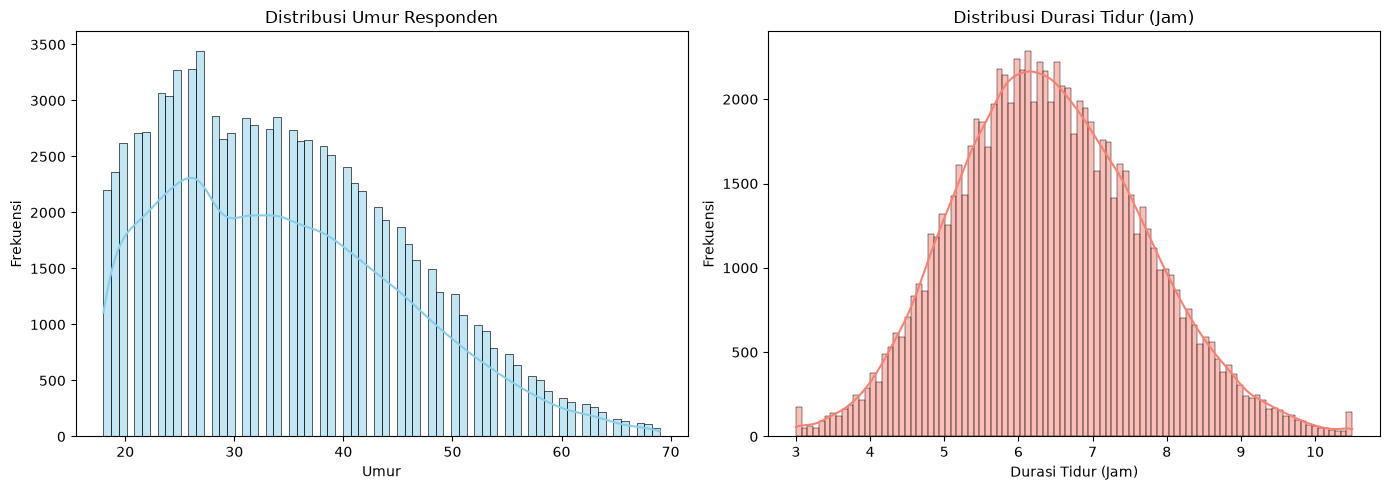

In [7]:
# D. Visualisasi Distribusi Fitur Numerik Utama (Umur & Durasi Tidur)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribusi Umur
sns.histplot(df['age'].dropna(), kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribusi Umur Responden')
axes[0].set_xlabel('Umur')
axes[0].set_ylabel('Frekuensi')

# Distribusi Durasi Tidur
sns.histplot(df['sleep_duration_hrs'].dropna(), kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Distribusi Durasi Tidur (Jam)')
axes[1].set_xlabel('Durasi Tidur (Jam)')
axes[1].set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

### E. Distribusi Fitur Tambahan (Skor Stres, Kualitas Tidur, BMI, & Gender)
Mari kita analisis juga sebaran data untuk tingkat stres, skor kualitas tidur, BMI, serta proporsi gender dalam dataset.


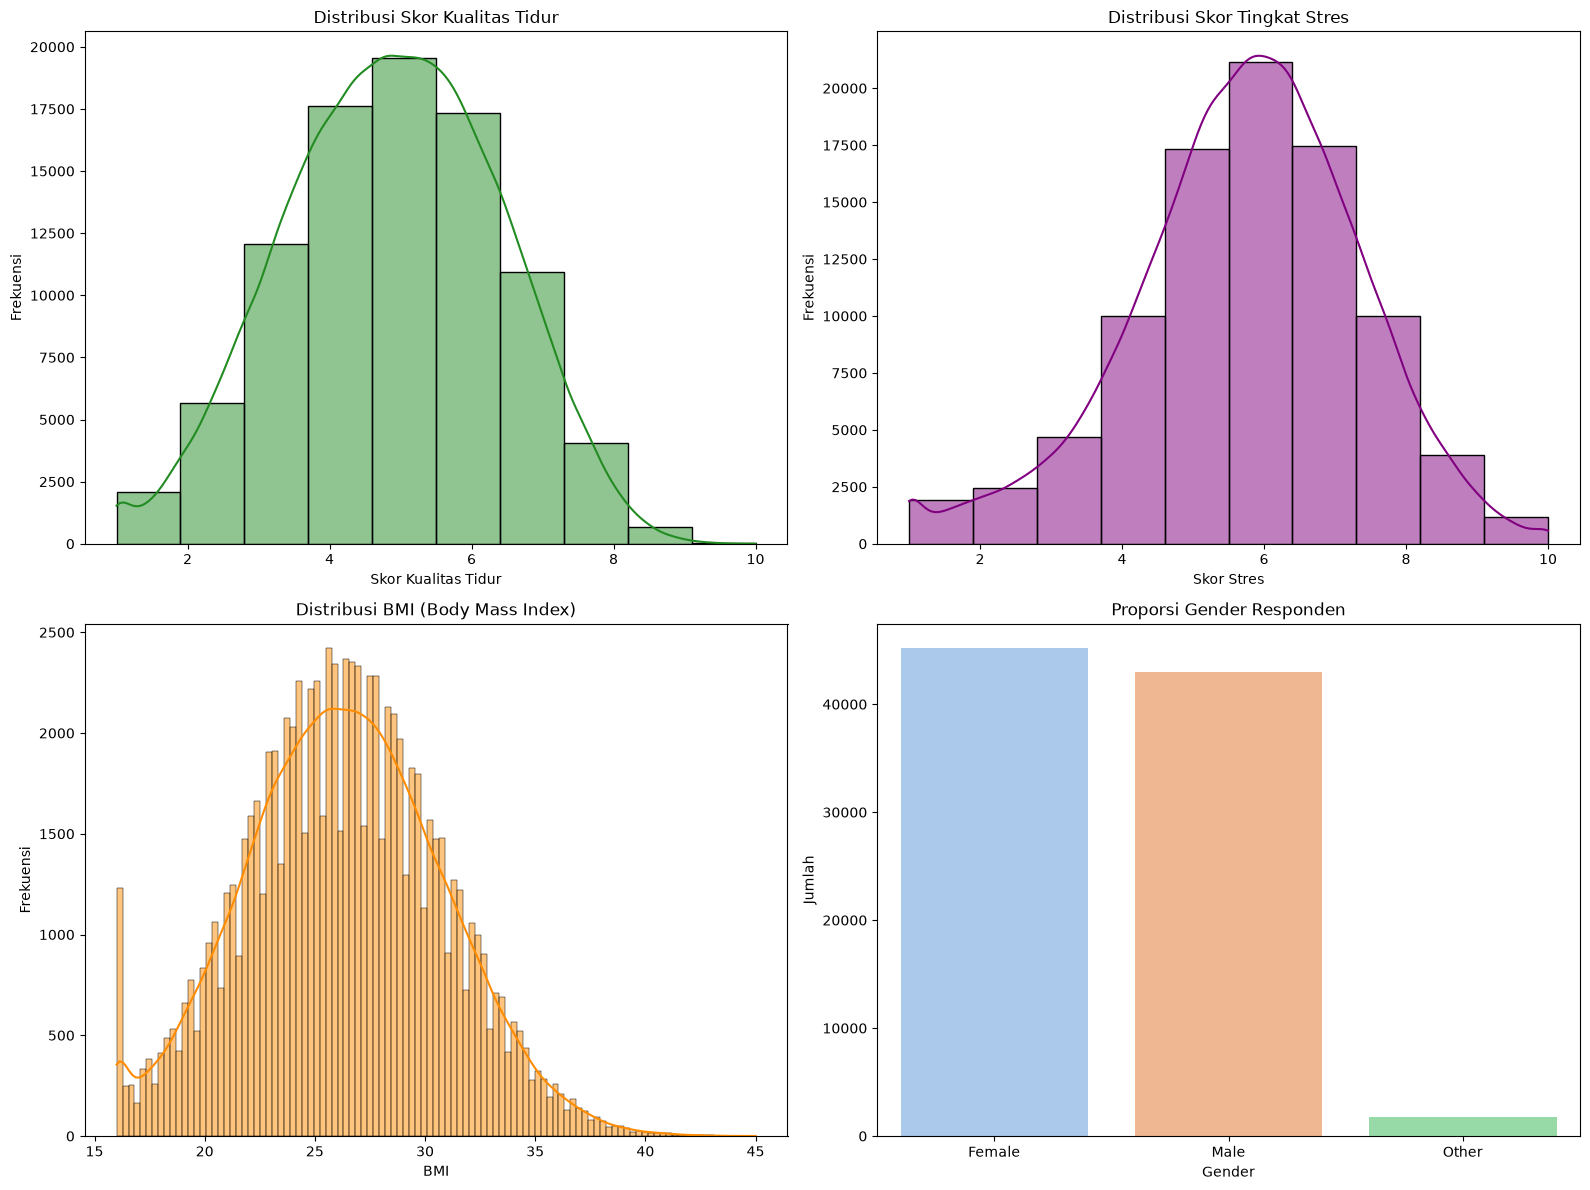

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Distribusi Skor Kualitas Tidur
sns.histplot(df['sleep_quality_score'].dropna(), bins=10, kde=True, ax=axes[0, 0], color='forestgreen')
axes[0, 0].set_title('Distribusi Skor Kualitas Tidur')
axes[0, 0].set_xlabel('Skor Kualitas Tidur')
axes[0, 0].set_ylabel('Frekuensi')

# 2. Distribusi Tingkat Stres
sns.histplot(df['stress_score'].dropna(), bins=10, kde=True, ax=axes[0, 1], color='purple')
axes[0, 1].set_title('Distribusi Skor Tingkat Stres')
axes[0, 1].set_xlabel('Skor Stres')
axes[0, 1].set_ylabel('Frekuensi')

# 3. Distribusi BMI
sns.histplot(df['bmi'].dropna(), kde=True, ax=axes[1, 0], color='darkorange')
axes[1, 0].set_title('Distribusi BMI (Body Mass Index)')
axes[1, 0].set_xlabel('BMI')
axes[1, 0].set_ylabel('Frekuensi')

# 4. Proporsi Gender
sns.countplot(data=df, x='gender', ax=axes[1, 1], palette='pastel', hue='gender', legend=False)
axes[1, 1].set_title('Proporsi Gender Responden')
axes[1, 1].set_xlabel('Gender')
axes[1, 1].set_ylabel('Jumlah')

plt.tight_layout()
plt.show()


### F. Eksplorasi Distribusi Fitur Tambahan Lainnya (Gaya Hidup & Pekerjaan)
Mari kita analisis juga bagaimana sebaran kebiasaan sebelum tidur dan latar belakang pekerjaan para responden dalam dataset ini.


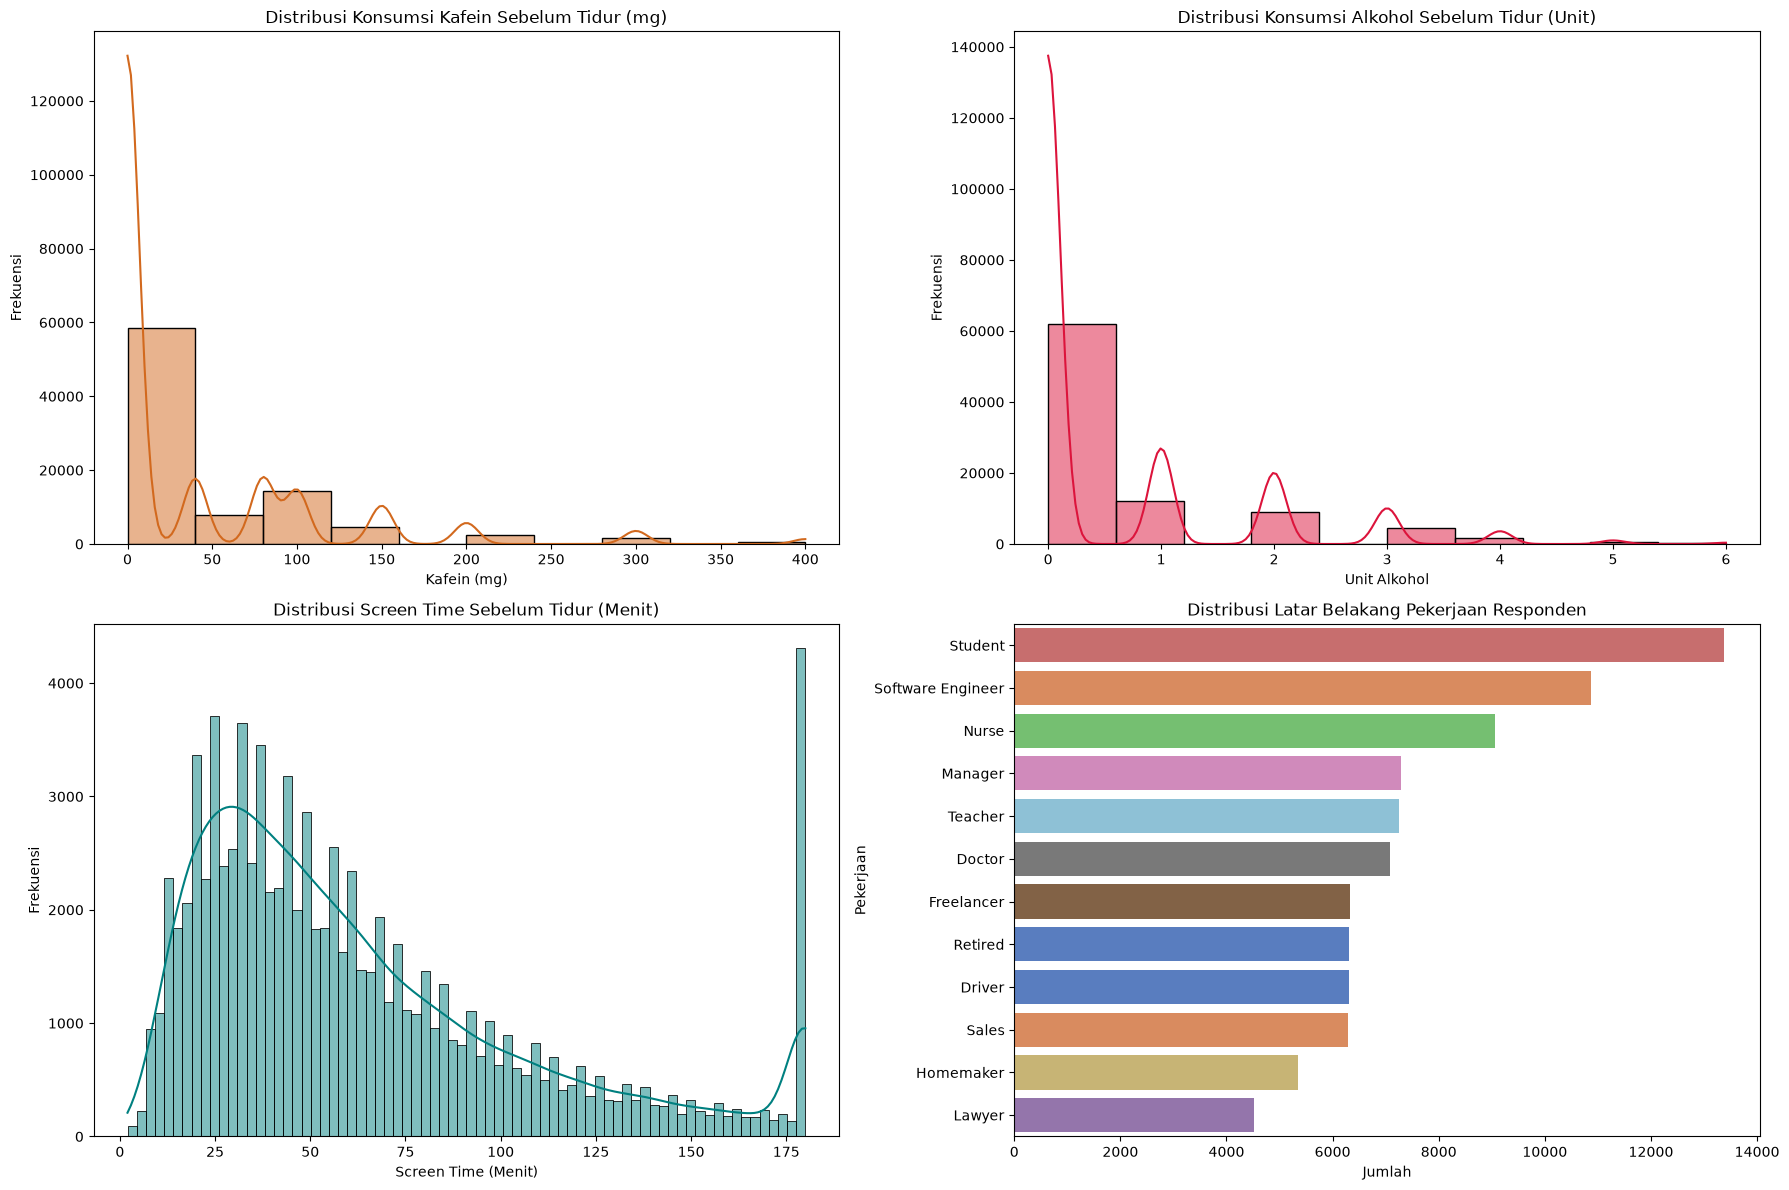

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# 1. Distribusi Konsumsi Kafein Sebelum Tidur
sns.histplot(df['caffeine_mg_before_bed'].dropna(), bins=10, kde=True, ax=axes[0, 0], color='chocolate')
axes[0, 0].set_title('Distribusi Konsumsi Kafein Sebelum Tidur (mg)')
axes[0, 0].set_xlabel('Kafein (mg)')
axes[0, 0].set_ylabel('Frekuensi')

# 2. Distribusi Konsumsi Alkohol Sebelum Tidur
sns.histplot(df['alcohol_units_before_bed'].dropna(), bins=10, kde=True, ax=axes[0, 1], color='crimson')
axes[0, 1].set_title('Distribusi Konsumsi Alkohol Sebelum Tidur (Unit)')
axes[0, 1].set_xlabel('Unit Alkohol')
axes[0, 1].set_ylabel('Frekuensi')

# 3. Distribusi Screen Time Sebelum Tidur
sns.histplot(df['screen_time_before_bed_mins'].dropna(), kde=True, ax=axes[1, 0], color='teal')
axes[1, 0].set_title('Distribusi Screen Time Sebelum Tidur (Menit)')
axes[1, 0].set_xlabel('Screen Time (Menit)')
axes[1, 0].set_ylabel('Frekuensi')

# 4. Distribusi Pekerjaan (Occupation)
sns.countplot(data=df, y='occupation', ax=axes[1, 1], order=df['occupation'].value_counts().index, palette='muted', hue='occupation', legend=False)
axes[1, 1].set_title('Distribusi Latar Belakang Pekerjaan Responden')
axes[1, 1].set_xlabel('Jumlah')
axes[1, 1].set_ylabel('Pekerjaan')

plt.tight_layout()
plt.show()

### H. Analisis Hubungan Dua Variabel Numerik Menggunakan Scatter Plot (Slide 12)
Sesuai Slide 12, **Scatter Plot** digunakan untuk melihat hubungan antara dua variabel numerik, menemukan pola/korelasi, serta mendeteksi pengelompokan (cluster) atau pencilan (outlier).


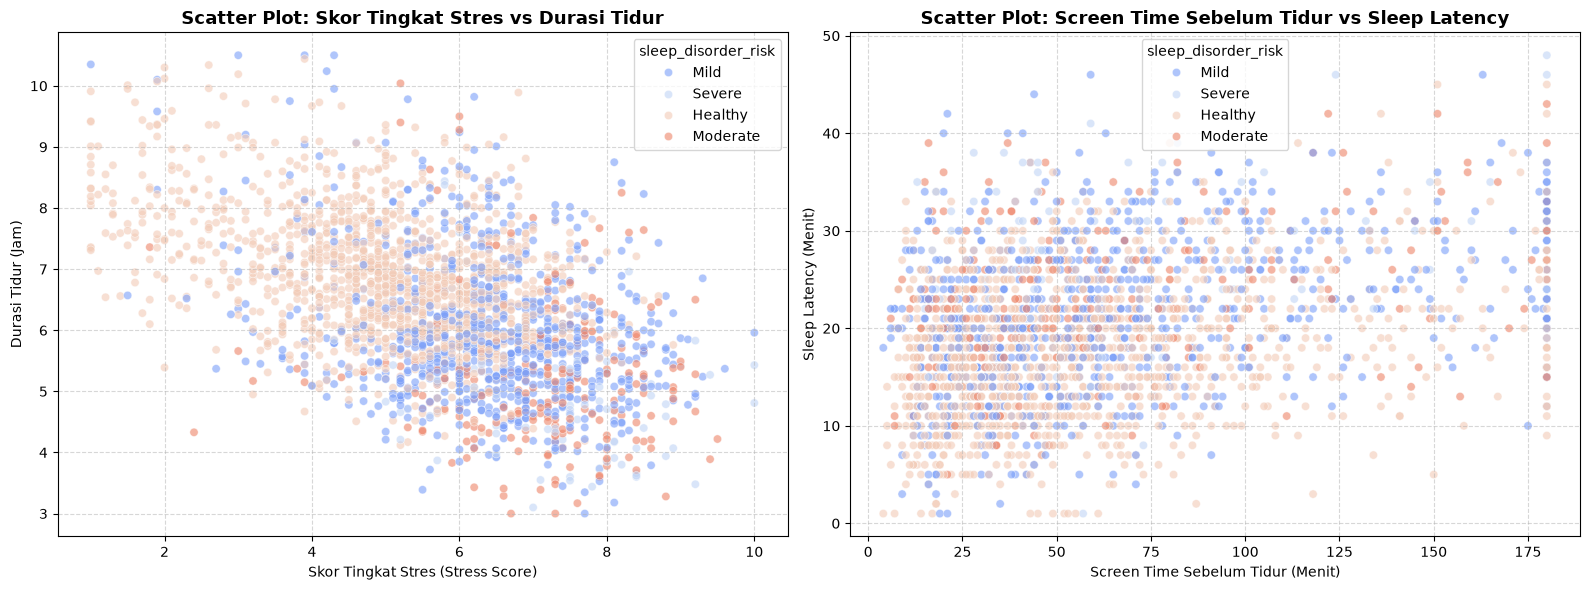

In [10]:
# Visualisasi Scatter Plot Antar Variabel Numerik (Slide 12)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Mengambil sampel 3.000 data acak agar scatter plot tidak terlalu padat dan cepat dirender
sample_df = df.sample(n=3000, random_state=42)

# 1. Hubungan Tingkat Stres vs Durasi Tidur
sns.scatterplot(data=sample_df, x='stress_score', y='sleep_duration_hrs',
                hue='sleep_disorder_risk', palette='coolwarm', alpha=0.6, ax=axes[0])
axes[0].set_title('Scatter Plot: Skor Tingkat Stres vs Durasi Tidur', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Skor Tingkat Stres (Stress Score)')
axes[0].set_ylabel('Durasi Tidur (Jam)')
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Hubungan Screen Time Sebelum Tidur vs Waktu Terlelap (Sleep Latency)
sns.scatterplot(data=sample_df, x='screen_time_before_bed_mins', y='sleep_latency_mins',
                hue='sleep_disorder_risk', palette='coolwarm', alpha=0.6, ax=axes[1])
axes[1].set_title('Scatter Plot: Screen Time Sebelum Tidur vs Sleep Latency', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Screen Time Sebelum Tidur (Menit)')
axes[1].set_ylabel('Sleep Latency (Menit)')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### I. Analisis Bentuk Distribusi Data & Skewness (Slide 16)
Sesuai Slide 16, distribusi data menunjukkan penyebaran nilai dalam dataset. Tiga bentuk distribusi yang umum:
1. **Negatively Skewed (Skew Left)**: Ekor distribusi di kiri, $\text{Mean} < \text{Median} < \text{Mode}$.
2. **Symmetric Distribution**: Distribusi seimbang, $\text{Mean} = \text{Median} = \text{Mode}$.
3. **Positively Skewed (Skew Right)**: Ekor distribusi di kanan, $\text{Mean} > \text{Median} > \text{Mode}$.


In [11]:
# Perhitungan Ukuran Bentuk Distribusi & Skewness (Slide 16)
num_cols = ['age', 'bmi', 'sleep_duration_hrs', 'sleep_quality_score', 'rem_percentage',
            'deep_sleep_percentage', 'sleep_latency_mins', 'caffeine_mg_before_bed',
            'alcohol_units_before_bed', 'screen_time_before_bed_mins', 'stress_score',
            'heart_rate_resting_bpm', 'cognitive_performance_score']

skew_list = []
for col in num_cols:
    s = df[col].dropna()
    mean_val = s.mean()
    median_val = s.median()
    mode_val = s.mode().iloc[0] if not s.mode().empty else None
    skew_val = s.skew()
    
    if skew_val > 0.5:
        shape = 'Positively Skewed (Mean > Median > Mode)'
    elif skew_val < -0.5:
        shape = 'Negatively Skewed (Mean < Median < Mode)'
    else:
        shape = 'Symmetric (Mean = Median = Mode)'
        
    skew_list.append({
        'Fitur Numerik': col,
        'Mean': round(mean_val, 2),
        'Median': round(median_val, 2),
        'Mode': round(mode_val, 2),
        'Skewness': round(skew_val, 3),
        'Bentuk Distribusi (Slide 16)': shape
    })

skew_table = pd.DataFrame(skew_list)
print('=== Rekapitulasi Bentuk Distribusi & Skewness Fitur Numerik ===')
display(skew_table)


=== Rekapitulasi Bentuk Distribusi & Skewness Fitur Numerik ===


,Fitur Numerik,Mean,Median,Mode,Skewness,Bentuk Distribusi (Slide 16)
0,age,34.70,33.00,27.00,0.552,Positively Skewed (Mean > Median > Mode)
1,bmi,26.29,26.30,16.00,0.074,Symmetric (Mean = Median = Mode)
2,sleep_duration_hrs,6.42,6.36,6.19,0.219,Symmetric (Mean = Median = Mode)
3,sleep_quality_score,4.87,4.90,4.80,-0.091,Symmetric (Mean = Median = Mode)
4,rem_percentage,20.24,20.30,20.30,-0.119,Symmetric (Mean = Median = Mode)
5,deep_sleep_percentage,20.25,20.30,30.00,-0.111,Symmetric (Mean = Median = Mode)
6,sleep_latency_mins,19.82,19.00,19.00,0.243,Symmetric (Mean = Median = Mode)
7,caffeine_mg_before_bed,38.72,0.00,0.00,2.381,Positively Skewed (Mean > Median > Mode)
8,alcohol_units_before_bed,0.60,0.00,0.00,1.927,Positively Skewed (Mean > Median > Mode)
9,screen_time_before_bed_mins,63.55,51.00,180.00,1.152,Positively Skewed (Mean > Median > Mode)


### J. Deteksi Nilai Ekstrem (Outlier) Menggunakan Metode IQR & Z-Score (Slide 13, 20, 21)
Sesuai Slide 20 & 21, **Outlier** adalah nilai yang jauh berbeda dari mayoritas data yang dapat memengaruhi statistik deskriptif dan performa model machine learning.

Dua metode deteksi outlier yang diimplementasikan:
1. **Metode IQR (Interquartile Range)**:
   $$\text{IQR} = Q3 - Q1$$
   $$\text{Outlier jika } x < Q1 - 1.5 \times \text{IQR} \quad \text{atau} \quad x > Q3 + 1.5 \times \text{IQR}$$
2. **Metode Z-Score**:
   $$Z = \frac{x - \mu}{\sigma}$$
   $$\text{Outlier jika } |Z| > 3$$


=== Tabel Rekapitulasi Deteksi Outlier (Metode IQR vs Z-Score) ===


,Variabel,Batas Bawah (IQR),Batas Atas (IQR),Outlier IQR,IQR (%),Outlier Z-Score (|Z|>3),Z-Score (%)
0,age,2.00,66.00,310,0.34%,193,0.21%
1,bmi,14.05,38.45,312,0.35%,127,0.14%
2,sleep_duration_hrs,2.92,9.88,495,0.55%,222,0.25%
3,sleep_quality_score,0.50,9.30,11,0.01%,11,0.01%
4,rem_percentage,11.10,29.50,699,0.78%,225,0.25%
5,deep_sleep_percentage,8.70,31.90,367,0.41%,159,0.18%
6,sleep_latency_mins,-2.50,41.50,328,0.36%,217,0.24%
7,caffeine_mg_before_bed,-120.00,200.00,2149,2.39%,2149,2.39%
8,alcohol_units_before_bed,-1.50,2.50,6787,7.54%,2244,2.49%
9,screen_time_before_bed_mins,-51.00,165.00,5198,5.78%,0,0.00%


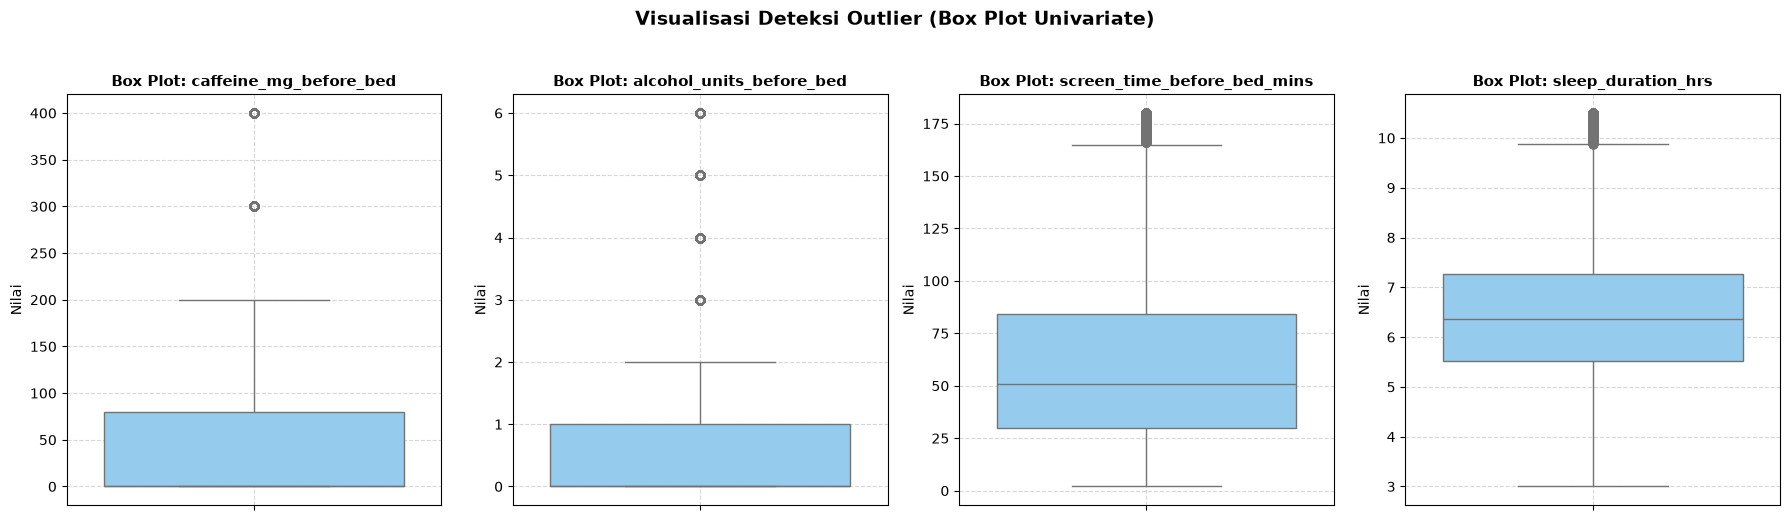

In [12]:
# Deteksi Outlier dengan Metode IQR dan Z-Score (Slide 21)
outlier_summary = []

for col in num_cols:
    s = df[col].dropna()
    # 1. Metode IQR
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    iqr_count = ((s < lower_bound) | (s > upper_bound)).sum()
    iqr_pct = (iqr_count / len(s)) * 100
    
    # 2. Metode Z-Score
    z_scores = (s - s.mean()) / s.std()
    z_count = (z_scores.abs() > 3).sum()
    z_pct = (z_count / len(s)) * 100
    
    outlier_summary.append({
        'Variabel': col,
        'Batas Bawah (IQR)': round(lower_bound, 2),
        'Batas Atas (IQR)': round(upper_bound, 2),
        'Outlier IQR': iqr_count,
        'IQR (%)': f'{iqr_pct:.2f}%',
        'Outlier Z-Score (|Z|>3)': z_count,
        'Z-Score (%)': f'{z_pct:.2f}%'
    })

outlier_df = pd.DataFrame(outlier_summary)
print('=== Tabel Rekapitulasi Deteksi Outlier (Metode IQR vs Z-Score) ===')
display(outlier_df)

# Visualisasi Box Plot Univariate untuk Fitur dengan Outlier Signifikan (Slide 13)
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
outlier_plot_cols = ['caffeine_mg_before_bed', 'alcohol_units_before_bed', 'screen_time_before_bed_mins', 'sleep_duration_hrs']

for ax, col in zip(axes, outlier_plot_cols):
    sns.boxplot(y=df[col].dropna(), ax=ax, color='lightskyblue')
    ax.set_title(f'Box Plot: {col}', fontsize=11, fontweight='bold')
    ax.set_ylabel('Nilai')
    ax.grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Visualisasi Deteksi Outlier (Box Plot Univariate)', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


### 7. Rangkuman Insight Awal untuk Tahap Data Preparation (Slide 22)

Berdasarkan hasil eksplorasi pada tahap **Data Understanding**, berikut adalah insight awal yang ditemukan beserta rekomendasi tindakan untuk tahap **Data Preparation** berikutnya:

1. **Identifikasi Masalah Kualitas Data (Data Quality Issues)**:
   - **Missing Values**: Ditemukan tepat **10.000 data hilang (10.0%)** pada 31 kolom atribut (hanya kolom target `sleep_disorder_risk` yang terisi 100%).
     * *Tindakan*: Lakukan imputasi data. Untuk variabel yang simetris gunakan **Mean / Median**, untuk variabel yang skewed gunakan **Median**, dan untuk fitur kategorik gunakan **Modus**.
   - **Duplikasi Data**: Ditemukan **0 data duplikat**, sehingga tidak diperlukan penghapusan baris ganda.
   - **Outlier**: Terdeteksi adanya nilai ekstrem pada fitur gaya hidup, terutama `caffeine_mg_before_bed`, `alcohol_units_before_bed`, dan `screen_time_before_bed_mins` baik dengan metode IQR maupun Z-Score.
     * *Tindakan*: Lakukan penanganan outlier dengan metode *capping / winsorization* atau gunakan algoritma machine learning yang tahan terhadap outlier (tree-based models).

2. **Karakteristik & Distribusi Data**:
   - Variabel biometrik seperti `bmi`, `sleep_duration_hrs`, dan `heart_rate_resting_bpm` cenderung memiliki distribusi simetris (*Symmetric Distribution*).
   - Variabel kebiasaan sebelum tidur (`caffeine`, `alcohol`, `screen_time`) memiliki distribusi *Positively Skewed* (condong ke kanan) dengan nilai mayoritas mendekati nol.
   - Variabel target `sleep_disorder_risk` didominasi oleh kelas **Healthy** (~54.2%) dan **Mild** (~33.5%), sedangkan kategori **Moderate** dan **Severe** lebih sedikit, mengindikasikan adanya ketidakseimbangan kelas (*imbalanced target*).

3. **Pola Hubungan Antar Variabel**:
   - Tingkat stres (`stress_score`) dan durasi tidur (`sleep_duration_hrs`) memiliki korelasi yang sangat kuat dengan tingkat risiko gangguan tidur.
   - Responden dengan skor stres tinggi dan durasi tidur rendah secara konsisten terkonsentrasi pada kategori risiko *Moderate* dan *Severe*.
